<a href="https://colab.research.google.com/github/David-NNdungu/econ5200-problem-set-2/blob/main/Problem%20Set%202/Econ_5200_PS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio
**David Ndungu · ECON 5200 · Experimentation lead**

My aim is to explain why the client's reported experiment wins do not translate
into the revenue they expect. I reconstruct a portfolio, compare estimated and
true gains, evaluate a different shipping rule, and test a method for monitoring
experiments without increasing false positives.

I use simulated experiments to study the client's decision process. The revenue
figures in my analysis describe that simulation; they are not measured client
revenues. I state my assumptions beside each step and trace my memo's numbers in
the final code cell. My Phase 4 design record is in [ai-appendix.md](ai-appendix.md).

## Setup

In [1]:
from pathlib import Path
import importlib, json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import log_ndtr
from IPython.display import display, Markdown

Path('src').mkdir(exist_ok=True)
Path('output').mkdir(exist_ok=True)
pd.set_option('display.precision', 4)
pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
CONFIG = {
    'N': 200, 'seed': 42, 'null_share': 0.80,
    'positive_low': 0.40, 'positive_high': 1.20,
    'n_min': 100, 'n_max': 5000, 'sigma': 10.0,
    'design_effect': 0.80, 'alpha': 0.05, 'near_zero_cutoff': 0.01,
    'annual_experiments': 200, 'dollars_per_effect_unit': 1000.0,
    'power_low_cut': 0.20, 'power_high_cut': 0.80, 'alternative_floor': 0.80,
    'bootstrap_B': 10000, 'bootstrap_seed': 1707, 'confidence_level': 0.95,
    'coverage_R': 200, 'coverage_B': 999, 'coverage_seed': 77000,
    'sequential_R': 1000, 'sequential_max_n': 5000,
    'sequential_seed': 20261027, 'path_seed': 20261028,
}
# rho is fixed from the planning effect, not fitted to null-check outcomes.
CONFIG['rho'] = 2 * CONFIG['sigma']**2 / CONFIG['design_effect']**2
print('Independent random generators; fixed seeds declared before analysis.')
print('Effect unit = $1,000 annual incremental revenue per deployment.')
print('Versions:', 'NumPy', np.__version__, 'pandas', pd.__version__)
import scipy
print('SciPy', scipy.__version__)

Independent random generators; fixed seeds declared before analysis.
Effect unit = $1,000 annual incremental revenue per deployment.
Versions: NumPy 2.1.3 pandas 2.2.3
SciPy 1.16.3


## Phase 1: Reconstruct the Portfolio (30 pts)
### Step 1.1: Simulate the experiment programme (15 pts)

**My prior and units.** I assign each experiment a true effect of exactly zero
with probability **0.80**. Otherwise, I draw its effect from Uniform(**0.40, 1.20**).
My prior therefore puts 80% of its probability at zero and 20% on positive effects.
I define one effect unit as **$1,000 in annual incremental revenue per deployed
change**, measured at a common rollout exposure. I use a known outcome SD of **10**
in those units. My prior excludes harmful effects; that is an assumption I revisit
when interpreting the recommendation.

**My sample-size design.** I draw each arm's sample size between 100 and 5,000 by
flooring a log-uniform draw on [100, 5,001). I use this range to include both small
and large experiments. With independent balanced arms, my standard error is
10 × sqrt(2 / n_per_arm). I draw the observed estimate from
Normal(true_effect, SE²), which has the same distribution as the difference
between two independent Gaussian arm means.

**My testing direction.** I define a win as a positive revenue effect. I use a
one-sided z test of H0: effect ≤ 0 against effect > 0, with
p = Normal.sf(estimate / SE). I fix this direction before inspecting the results
and apply the client's rule, p < 0.05. The brief leaves sidedness unspecified,
so I state my choice here.

**My definitions.** I call an effect near zero when |true effect| ≤ 0.01.
Because my positive component starts at 0.40, this identifies exactly the planted
nulls. I count a real win when a shipped experiment has a positive true effect.
My false-ship rate is false ships divided by all ships. It has a different
denominator from the Type I error rate, which conditions on null experiments.

In [2]:
def simulate_inline(n, seed, null_share=0.80, positive_low=0.40,
                    positive_high=1.20, n_min=100, n_max=5000,
                    sigma=10.0, design_effect=0.80, alpha=0.05):
    r = np.random.default_rng(seed)
    is_null = r.random(n) < null_share
    positive_draw = r.uniform(positive_low, positive_high, n)
    truth = np.where(is_null, 0.0, positive_draw)
    n_per_arm = np.minimum(np.floor(np.exp(r.uniform(
        np.log(n_min), np.log(n_max + 1), n))).astype(int), n_max)
    se = sigma * np.sqrt(2 / n_per_arm)
    estimate = r.normal(truth, se)
    critical_z = stats.norm.isf(alpha)
    return pd.DataFrame({
        'experiment_id': np.arange(1, n + 1), 'true_effect': truth,
        'is_null': is_null, 'n_per_arm': n_per_arm, 'n_total': 2*n_per_arm,
        'estimate': estimate, 'se': se, 'z': estimate/se,
        'p_value': stats.norm.sf(estimate/se),
        'design_effect': np.full(n, design_effect),
        'design_power': stats.norm.sf(critical_z-design_effect/se),
        'oracle_power': stats.norm.sf(critical_z-truth/se),
    })

SIM_PARAMS = {k: CONFIG[k] for k in ['null_share', 'positive_low', 'positive_high',
    'n_min', 'n_max', 'sigma', 'design_effect', 'alpha']}
log = simulate_inline(CONFIG['N'], CONFIG['seed'], **SIM_PARAMS)
near_zero = log.true_effect.abs() <= CONFIG['near_zero_cutoff']
assert np.array_equal(near_zero, log.is_null)
assert len(log) == 200 and log.experiment_id.is_unique
assert log.n_per_arm.between(CONFIG['n_min'], CONFIG['n_max']).all()
display(log.head(10))
print('Prior:', {'point_mass_zero': CONFIG['null_share'],
                 'positive_uniform': (CONFIG['positive_low'], CONFIG['positive_high'])})
print('Realised null share:', log.is_null.mean(), '(a random draw, not forced to 80%)')
print('Sample sizes per arm:', log.n_per_arm.min(), 'to', log.n_per_arm.max())
print('True positives:', int((~log.is_null).sum()))

,experiment_id,true_effect,is_null,n_per_arm,n_total,estimate,se,z,p_value,design_effect,design_power,oracle_power
0,1,0.0000,True,325,650,0.9790,0.7845,1.2479,0.1060,0.8,0.2660,0.0500
1,2,0.0000,True,3634,7268,-0.0592,0.2346,-0.2525,0.5997,0.8,0.9612,0.0500
2,3,0.8006,False,2125,4250,0.9121,0.3068,2.9731,0.0015,0.8,0.8322,0.8327
3,4,0.0000,True,154,308,-2.7464,1.1396,-2.4099,0.9920,0.8,0.1729,0.0500
4,5,0.0000,True,4943,9886,-0.2326,0.2011,-1.1563,0.8762,0.8,0.9902,0.0500
5,6,0.5837,False,3117,6234,0.5093,0.2533,2.0106,0.0222,0.8,0.9349,0.7452
6,7,0.0000,True,303,606,-0.8710,0.8124,-1.0721,0.8582,0.8,0.2546,0.0500
7,8,0.0000,True,2642,5284,0.1966,0.2751,0.7144,0.2375,0.8,0.8967,0.0500
8,9,0.0000,True,151,302,2.2986,1.1509,1.9973,0.0229,0.8,0.1711,0.0500
9,10,0.0000,True,4983,9966,-0.2357,0.2003,-1.1766,0.8803,0.8,0.9906,0.0500


Prior: {'point_mass_zero': 0.8, 'positive_uniform': (0.4, 1.2)}
Realised null share: 0.825 (a random draw, not forced to 80%)
Sample sizes per arm: 102 to 4983
True positives: 35


### Step 1.2: Apply the client's rule (15 pts)

In [3]:
log['client_ship'] = log.p_value < CONFIG['alpha']
shipped = log.loc[log.client_ship].copy()
ship_count = len(shipped)
false_ship_count = int(shipped.is_null.sum())
false_ship_rate = false_ship_count / ship_count
real_win_count = ship_count - false_ship_count
real_win_share = real_win_count / ship_count
mean_true = shipped.true_effect.mean()
mean_estimated = shipped.estimate.mean()
realised_return = shipped.true_effect.sum()
announced_return = shipped.estimate.sum()
annual_scale = CONFIG['annual_experiments'] / len(log)
annual_realised_dollars = realised_return * annual_scale * CONFIG['dollars_per_effect_unit']
annual_announced_dollars = announced_return * annual_scale * CONFIG['dollars_per_effect_unit']
annual_overstatement_dollars = annual_announced_dollars - annual_realised_dollars
oracle_return = log.true_effect.sum()
annual_missed_uplift_dollars = (oracle_return-realised_return)*annual_scale*CONFIG['dollars_per_effect_unit']
audit = pd.Series({
    'experiments': len(log), 'ships': ship_count, 'ship_rate': ship_count/len(log),
    'false_ships': false_ship_count, 'false_ship_share': false_ship_rate,
    'real_wins': real_win_count, 'real_win_share': real_win_share,
    'mean_true_effect': mean_true, 'mean_estimated_effect': mean_estimated,
    'mean_overstatement': mean_estimated-mean_true,
    'realised_return_units': realised_return, 'announced_return_units': announced_return,
    'annual_realised_dollars': annual_realised_dollars,
    'annual_forecast_overstatement_dollars': annual_overstatement_dollars,
    'annual_oracle_missed_uplift_dollars': annual_missed_uplift_dollars,
})
display(audit.to_frame('value'))
display(Markdown(f"**Finding:** {ship_count} tests ship ({ship_count/len(log):.1%}); "
    f"{false_ship_count} are null ({false_ship_rate:.1%} of ships). "
    f"The estimated mean is {mean_estimated:.3f} units versus a true mean of "
    f"{mean_true:.3f}. This selection-induced exaggeration is the **winner's curse**."))

,value
experiments,200.0000
ships,26.0000
ship_rate,0.1300
false_ships,8.0000
false_ship_share,0.3077
real_wins,18.0000
real_win_share,0.6923
mean_true_effect,0.6210
mean_estimated_effect,1.3156
mean_overstatement,0.6946


**Finding:** 26 tests ship (13.0%); 8 are null (30.8% of ships). The estimated mean is 1.316 units versus a true mean of 0.621. This selection-induced exaggeration is the **winner's curse**.

My headline ship rate does not tell me how many tests create revenue.
Most candidates in my prior are null, and the shipping rule selects estimates
that look unusually favorable. As a result, the average estimate among shipped
experiments is an optimistic forecast of their true gain.

**My measure of cost.** I measure annual forecast overstatement: the sum of
shipped estimates minus the sum of shipped true effects, scaled to 200 experiments
and converted to dollars. I do not treat this as implementation spending because
I have no deployment-cost data. I also report missed uplift relative to an oracle
that knows every true effect, as a benchmark I could not achieve in practice.
My annual conversion assumes common rollout exposure, additive gains, no
interactions between deployments, and a stable experiment programme.

## Phase 2: The Winner's Curse (35 pts)
### Step 2.1: Quantify the exaggeration (20 pts)

I measure inflation as **mean estimated effect / mean true effect among ships**.
I avoid averaging individual ratios because null experiments have a zero
denominator. I also report the absolute gap so the result remains interpretable
when a tier has little or no true return.

I group experiments using prospective power at my fixed planning effect of
**0.80 units**: low < 20%, medium 20%–<80%, and high ≥ 80%. My approach keeps
unknown truth and selected estimates out of the implementable power rule.
I retain power at each true effect in the log for diagnosis only.

,all_tests,ships,mean_true,mean_estimated,absolute_inflation,inflation_factor,false_ship_share
power_tier,,,,,,,
Low,41,3,0.000,2.4432,2.4432,NaN,1.0000
Medium,111,15,0.694,1.4008,0.7068,2.0185,0.2667
High,48,8,0.717,0.7329,0.0159,1.0221,0.1250


Overall ratio of means: 2.118485827156141


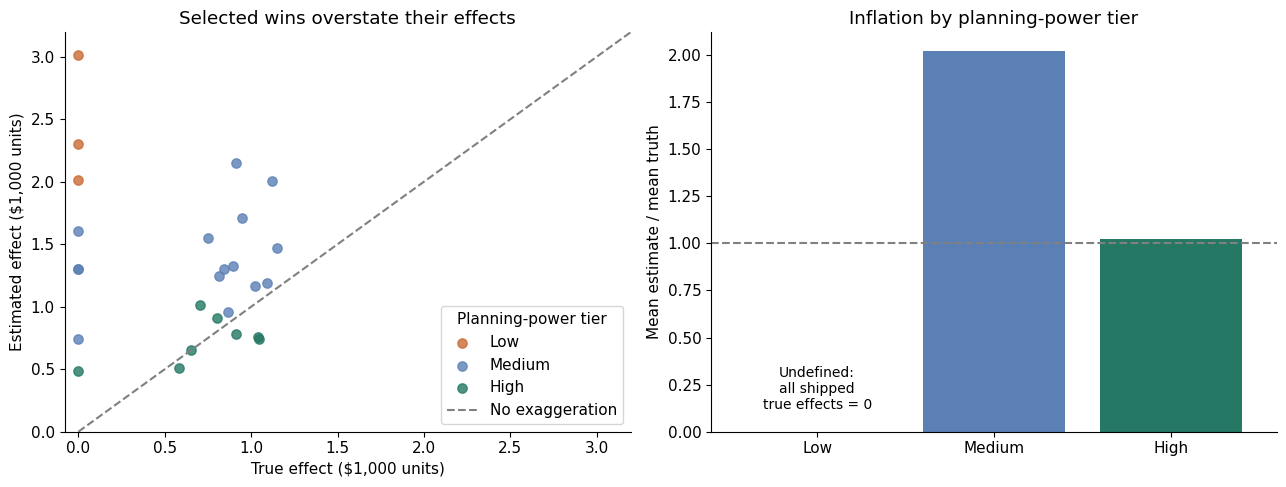

In the low-power tier, all **3** ships are null. Their mean true effect is zero and their mean estimate is **2.443** units. The absolute exaggeration is therefore identifiable, but the multiplicative inflation factor is undefined; reporting a finite ratio would conceal the zero denominator.

In [4]:
log['power_tier'] = pd.cut(log.design_power, [-np.inf, CONFIG['power_low_cut'],
    CONFIG['power_high_cut'], np.inf], labels=['Low', 'Medium', 'High'], right=False)
shipped = log.loc[log.client_ship].copy()
inflation = mean_estimated / mean_true
tier_rows = []
for tier in ['Low', 'Medium', 'High']:
    all_g = log.loc[log.power_tier == tier]
    g = all_g.loc[all_g.client_ship]
    mt, me = g.true_effect.mean(), g.estimate.mean()
    tier_rows.append({'power_tier':tier, 'all_tests':len(all_g), 'ships':len(g),
        'mean_true':mt, 'mean_estimated':me, 'absolute_inflation':me-mt,
        'inflation_factor':me/mt if mt > 0 else np.nan,
        'false_ship_share':g.is_null.mean()})
tier_table = pd.DataFrame(tier_rows).set_index('power_tier')
display(tier_table)
print('Overall ratio of means:', inflation)

fig, axes = plt.subplots(1,2,figsize=(13,5))
colors = {'Low':'#ca6b34','Medium':'#5b80b5','High':'#257864'}
for tier, color in colors.items():
    g = shipped.loc[shipped.power_tier == tier]
    axes[0].scatter(g.true_effect, g.estimate, label=tier, color=color, alpha=.8, s=45)
lim = max(shipped.estimate.max(), shipped.true_effect.max())*1.06
axes[0].plot([0,lim],[0,lim],color='gray',ls='--',label='No exaggeration')
axes[0].set(xlabel='True effect ($1,000 units)', ylabel='Estimated effect ($1,000 units)',
            title='Selected wins overstate their effects', xlim=(-.08,lim), ylim=(0,lim))
axes[0].legend(title='Planning-power tier')
positions = np.arange(3)
axes[1].bar(positions, tier_table.inflation_factor, color=list(colors.values()))
axes[1].set_xticks(positions, ['Low', 'Medium', 'High'])
axes[1].set_xlim(-.6, 2.6)
for j, tier in enumerate(tier_table.index):
    if not np.isfinite(tier_table.loc[tier,'inflation_factor']):
        axes[1].text(j,.12,'Undefined:\nall shipped\ntrue effects = 0',ha='center',fontsize=10)
axes[1].axhline(1,color='gray',ls='--')
axes[1].set(ylabel='Mean estimate / mean truth',title='Inflation by planning-power tier')
fig.tight_layout()
fig.savefig('output/winners_curse.png', dpi=160, bbox_inches='tight')
plt.show()
low = tier_table.loc['Low']
display(Markdown(f"In the low-power tier, all **{int(low.ships)}** ships are null. "
    f"Their mean true effect is zero and their mean estimate is **{low.mean_estimated:.3f}** "
    "units. The absolute exaggeration is therefore identifiable, but the multiplicative "
    "inflation factor is undefined; reporting a finite ratio would conceal the zero denominator."))

**My explanation of the winner's curse.** An estimate is more likely to pass
the threshold when random noise pushes it upward. Once I look only at shipped
tests, I have selected favorable noise along with real effects. The selected
estimates therefore overstate the true gains on average.

A small experiment has a large standard error relative to a plausible effect.
It needs more favorable noise to pass, so I expect its apparent wins to be more
exaggerated. This is the same selection mechanism behind publication bias and
low positive predictive value in weak studies.

I read my tier table as one portfolio, not a guarantee that every seed produces
strictly ordered ratios. I use the counts and absolute gaps alongside the ratios.
In my low-power tier, every ship is null, so the ratio is undefined. The positive
estimated gains and zero true gains still give a clear absolute overstatement.

### Step 2.2: The bootstrap where the formula fails (15 pts)

My return statistic is R = sum(true_effect × client_ship), across **all 200 rows**.
I resample complete experiments, including those that do not ship. If I resampled
only winners, I would omit variation in how many tests ship.

My shipping rule is fixed and does not refit anything. Resampling its stored
per-row contributions is therefore equivalent to resampling rows and reapplying
the rule. I preserve each row's relationship between truth, estimate, standard
error and decision.

I first compute the bootstrap distribution with my explicit loop. I then give
SciPy the same generator seed and compare all replicate values. I report BCa,
percentile and basic intervals. BCa adjusts for bias and jackknife acceleration;
I still need to check whether my resampling scheme is appropriate.

,Low (units),High (units)
Percentile,9.3099,23.8003
Basic,8.4917,22.9821
BCa,10.0187,24.7111


Manual/SciPy max replicate difference: 0.0
Manual SE / SciPy SE: 3.7008005667142903 3.7008005667142903
Warnings: []


,diagnostic
independent_experiments,200
nonzero_contributions,18
distinct_bootstrap_returns,10000
bootstrap_skewness,0.2299
jackknife_acceleration_denominator,301.8839
largest_contribution_share,0.0712
finite_BCa_endpoints,True


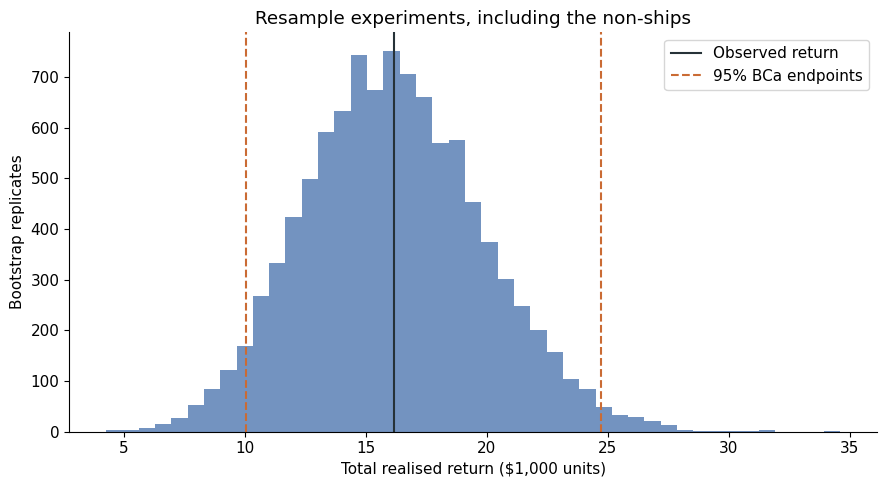

In [5]:
contribution = np.where(log.client_ship, log.true_effect, 0.0)
boot_rng = np.random.default_rng(CONFIG['bootstrap_seed'])
manual_boot = np.empty(CONFIG['bootstrap_B'])
for b in range(CONFIG['bootstrap_B']):
    sampled_rows = boot_rng.integers(0, len(log), size=len(log))
    manual_boot[b] = contribution[sampled_rows].sum()

with warnings.catch_warnings(record=True) as caught_boot:
    warnings.simplefilter('always')
    scipy_boot = stats.bootstrap((contribution,), np.sum,
        n_resamples=CONFIG['bootstrap_B'], vectorized=True, batch=500,
        confidence_level=CONFIG['confidence_level'], method='BCa',
        rng=np.random.default_rng(CONFIG['bootstrap_seed']))
max_boot_difference = np.max(np.abs(manual_boot-scipy_boot.bootstrap_distribution))
assert np.allclose(manual_boot, scipy_boot.bootstrap_distribution, rtol=0, atol=1e-12)
boot_se = manual_boot.std(ddof=1)
bca_low, bca_high = map(float, scipy_boot.confidence_interval)
assert np.isfinite([bca_low,bca_high]).all() and bca_low < bca_high
percentile_ci = np.quantile(manual_boot, [.025,.975])
basic_ci = 2*realised_return-percentile_ci[::-1]
display(pd.DataFrame([percentile_ci,basic_ci,[bca_low,bca_high]],
    index=['Percentile','Basic','BCa'], columns=['Low (units)','High (units)']))
print('Manual/SciPy max replicate difference:', max_boot_difference)
print('Manual SE / SciPy SE:', boot_se, scipy_boot.standard_error)
print('Warnings:', [str(w.message) for w in caught_boot])

# Lab 7 Diagnosis 1: variation and the jackknife denominator must not vanish.
jackknife = contribution.sum()-contribution
jack_dev = jackknife.mean()-jackknife
jack_denominator = 6*(np.sum(jack_dev**2)**1.5)
diagnostics = pd.Series({
    'independent_experiments': len(log),
    'nonzero_contributions': np.count_nonzero(contribution),
    'distinct_bootstrap_returns': len(np.unique(manual_boot)),
    'bootstrap_skewness': stats.skew(manual_boot),
    'jackknife_acceleration_denominator': jack_denominator,
    'largest_contribution_share': contribution.max()/contribution.sum(),
    'finite_BCa_endpoints': np.isfinite([bca_low,bca_high]).all(),
})
display(diagnostics.to_frame('diagnostic'))
assert jack_denominator > 0 and boot_se > 0

fig, ax = plt.subplots()
ax.hist(manual_boot,bins=45,color='#5b80b5',alpha=.85)
ax.axvline(realised_return,color='#263238',label='Observed return')
ax.axvline(bca_low,color='#ca6b34',ls='--',label='95% BCa endpoints')
ax.axvline(bca_high,color='#ca6b34',ls='--')
ax.set(xlabel='Total realised return ($1,000 units)', ylabel='Bootstrap replicates',
       title='Resample experiments, including the non-ships')
ax.legend(); fig.tight_layout()
fig.savefig('output/bootstrap_return.png',dpi=160,bbox_inches='tight'); plt.show()

**My checks before trusting the interval.**

| Connection | My check and interpretation |
|---|---|
| Lab 7 Diagnosis 1: degenerate bootstrap | I use an additive sum, not a discrete median. I check positive bootstrap SD, a nonzero jackknife denominator and finite BCa endpoints. |
| Lab 7 Diagnosis 2: silent undercoverage, skewness and wrong target | I define the target explicitly, inspect the distribution, compare interval methods and measure coverage on fresh portfolios below. |
| Lab 7 Diagnosis 3: dependence and the resampling unit | I independently generate experiments and resample whole experiments. If tests shared users or releases, I would need a dependence-aware method. |
| Too little information and rare outcomes | I report the nonzero contribution count and largest contribution's share. Extra resamples cannot create positive experiments missing from my data. |
| Heavy tails | My planted effects are bounded in [0, 1.20], so return contributions have finite variance. I base this check on the data-generating model, not just the histogram. |
| Nonsmooth extrema, boundaries and fitted selection | I bootstrap a sum under a fixed rule. If I fitted a rule on these data, I would need to repeat that fit inside each resample. |
| Time dependence and drift | My simulation has neither. I would reconsider ordinary row resampling for a changing real-world programme or a dependent time series. |

**My interpretation.** I already know the realised return of this simulated
portfolio because I planted the truth. I use BCa to estimate uncertainty in
**200 times the population mean return of comparable experiments**, or expected
annual programme return. I do not interpret it as uncertainty about known
planted values or as a prediction interval for one future year's realised return.
My interval also leaves out uncertainty in the prior, revenue scaling and model
assumptions.

In [6]:
# Lab 7 Diagnosis 2-style coverage check on fresh portfolios (separate seeds).
# Compute the population target by deterministic Gaussian quadrature over effects
# and the exact probabilities of the floored log-uniform sample-size design.
nodes, weights = np.polynomial.legendre.leggauss(60)
delta_nodes = ((CONFIG['positive_high']-CONFIG['positive_low'])*nodes/2
               +(CONFIG['positive_high']+CONFIG['positive_low'])/2)
sizes = np.arange(CONFIG['n_min'], CONFIG['n_max']+1)
size_probs = np.log((sizes+1)/sizes)/np.log((CONFIG['n_max']+1)/CONFIG['n_min'])
node_se = CONFIG['sigma']*np.sqrt(2/sizes)
ship_probability = stats.norm.sf(stats.norm.isf(CONFIG['alpha'])
                                -delta_nodes[:,None]/node_se[None,:])
expected_annual_return = (CONFIG['annual_experiments']*(1-CONFIG['null_share'])
    *np.sum((weights/2)*delta_nodes*(ship_probability @ size_probs)))
coverage_hits = 0
coverage_failures = 0
for rep in range(CONFIG['coverage_R']):
    fresh = simulate_inline(CONFIG['N'],CONFIG['coverage_seed']+rep,**SIM_PARAMS)
    y = np.where(fresh.p_value < CONFIG['alpha'],fresh.true_effect,0.0)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',stats.DegenerateDataWarning)
        interval = stats.bootstrap((y,),np.sum,n_resamples=CONFIG['coverage_B'],
            method='BCa',batch=250,rng=np.random.default_rng(CONFIG['coverage_seed']+10000+rep)
            ).confidence_interval
    finite = np.isfinite(interval).all()
    coverage_failures += not finite
    coverage_hits += finite and interval.low <= expected_annual_return <= interval.high
coverage_rate = coverage_hits/CONFIG['coverage_R']
coverage_mcse = np.sqrt(coverage_rate*(1-coverage_rate)/CONFIG['coverage_R'])
print('Expected annual return target (units):',expected_annual_return)
print('Coverage:',coverage_hits,'/',CONFIG['coverage_R'], '=',f'{coverage_rate:.1%}')
print('Coverage Monte Carlo SE:',f'{coverage_mcse:.2%}','; nonfinite intervals:',coverage_failures)
display(Markdown(f'The measured coverage is **{coverage_rate:.1%}** (MC SE '
    f'**{coverage_mcse:.2%}**) versus nominal **95%**. '
    'This is a limited diagnostic under the stated prior, not a universal coverage guarantee.'))

Expected annual return target (units): 16.91675378463708
Coverage: 187 / 200 = 93.5%
Coverage Monte Carlo SE: 1.74% ; nonfinite intervals: 0


The measured coverage is **93.5%** (MC SE **1.74%**) versus nominal **95%**. This is a limited diagnostic under the stated prior, not a universal coverage guarantee.

## Phase 3: A Rule They Can Adopt (25 pts)
### Step 3.1: Design the alternative (20 pts)

My alternative ships an experiment when **p < 0.05 and prospective power at my
0.80-unit planning effect is at least 80%**. I calculate power from the standard
error and planning effect, without using planted truth. My planning effect is
$800 in annual revenue per deployment, chosen as the effect my design should
be able to detect.

For a future test, my required sample size per arm is
ceil(2 × sigma² × (z_0.95 + z_0.80)² / planning_effect²).

I compare rules on the **same completed portfolio**. This comparison filters
the experiments already run; I do not resize tests or generate replacement
results. I also show p < 0.01 as a threshold sensitivity check.

In [7]:
alternative_ship = log.client_ship & (log.design_power >= CONFIG['alternative_floor'])
strict_ship = log.p_value < .01
def audit_mask(frame,mask):
    count = int(mask.sum())
    false = int(frame.loc[mask,'is_null'].sum())
    return {'realised_return': float(frame.loc[mask,'true_effect'].sum()),
            'ship_count':count, 'false_ship_count':false,
            'false_ship_rate':false/count if count else np.nan}
comparison = pd.DataFrame({
    'Client: p < .05': audit_mask(log,log.client_ship),
    'Alternative: p < .05 & power >= .80':audit_mask(log,alternative_ship),
    'Sensitivity: p < .01':audit_mask(log,strict_ship),
}).T
comparison['annual_return_dollars'] = comparison.realised_return*annual_scale*CONFIG['dollars_per_effect_unit']
display(comparison)
alternative_return = comparison.iloc[1].realised_return
alternative_count = int(comparison.iloc[1].ship_count)
alternative_false_rate = comparison.iloc[1].false_ship_rate
alternative_annual_dollars = comparison.iloc[1].annual_return_dollars
return_sacrifice_dollars = annual_realised_dollars-alternative_annual_dollars
required_n_per_arm = int(np.ceil(2*CONFIG['sigma']**2 * (
    stats.norm.isf(CONFIG['alpha'])+stats.norm.ppf(CONFIG['alternative_floor']))**2
    /CONFIG['design_effect']**2))
print('Required n per arm for planning-power floor:',required_n_per_arm)
print('Annual return sacrificed by retrospective filter ($):',return_sacrifice_dollars)
assert (alternative_ship <= log.client_ship).all()
display(Markdown(f'The power floor ships **{alternative_count}** rather than **{ship_count}**, '
    f'with false-ship share **{alternative_false_rate:.1%}** rather than **{false_ship_rate:.1%}**. '
    f'Annual realised revenue falls from **${annual_realised_dollars:,.0f}** to '
    f'**${alternative_annual_dollars:,.0f}**. It is **not** the return winner.'))

,realised_return,ship_count,false_ship_count,false_ship_rate,annual_return_dollars
Client: p < .05,16.1460,26.0,8.0,0.3077,16145.9707
Alternative: p < .05 & power >= .80,5.7362,8.0,1.0,0.1250,5736.1917
Sensitivity: p < .01,14.9107,17.0,1.0,0.0588,14910.6939


Required n per arm for planning-power floor: 1933
Annual return sacrificed by retrospective filter ($): 10409.779012433777


The power floor ships **8** rather than **26**, with false-ship share **12.5%** rather than **30.8%**. Annual realised revenue falls from **$16,146** to **$5,736**. It is **not** the return winner.

**My recommendation and its limits.** I recommend the power floor when the
client values fewer false deployments and more credible forecasts. I would pair
it with the Phase 4 sequential method when the client monitors tests as they run.

My comparison does not show a revenue improvement. The filter rejects some
genuinely profitable experiments. Under my zero-or-positive prior and zero
deployment costs, excluding a null cannot increase return, while excluding a
positive effect lowers it. My approach makes the difference between evidence
quality and total realised return explicit.

If cost-free total true return is the CFO's only objective, I would retain the
client's rule over this filter. For a future programme, I would plan sufficient
sample sizes before launch. I have not estimated the costs or benefits of that
resizing. Actual deployment costs or harmful effects could change which rule
is best, so I would collect that information before making a profit claim.

### Step 3.2: Ship the module (5 pts, its own rubric row)

I write my reusable functions to src/experiment_portfolio.py below, then import
them and compare their results with the notebook. Keeping the file-writing cell
in the notebook lets me recreate the module in a fresh Colab session.

In [8]:
%%writefile src/experiment_portfolio.py
"""Reproducible experiment portfolios and deployable rules for ECON 5200 PS2.

Effects are standardized annual revenue units per deployment; one unit means
$1,000. Truth is retained for simulation audits and never used by apply_rule.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Literal

import numpy as np
import pandas as pd
from scipy import stats


@dataclass(frozen=True)
class Rule:
    """A positive-direction p-value threshold, optionally with a design-power floor."""
    kind: Literal["threshold", "power_floor"] = "threshold"
    alpha: float = 0.05
    min_power: float = 0.80


def simulate_portfolio(
    n: int = 200, seed: int = 42, *, null_share: float = 0.80,
    positive_low: float = 0.40, positive_high: float = 1.20,
    n_min: int = 100, n_max: int = 5000, sigma: float = 10.0,
    design_effect: float = 0.80, alpha: float = 0.05,
) -> pd.DataFrame:
    """Simulate independent balanced A/B tests with known Gaussian outcome SD.

    Prior: point mass at zero with probability null_share, otherwise a positive
    Uniform(positive_low, positive_high). Sample sizes per arm are floor of a
    log-uniform draw on [n_min, n_max+1), capped at n_max. With n observations
    in EACH arm, SE = sigma*sqrt(2/n). Use a pre-specified one-sided z test.
    design_power uses a common, observable planning effect; oracle_power uses
    truth and is for diagnosis ONLY. Seeds are fixed before inspecting results.
    """
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer")
    if (not 0 <= null_share <= 1 or not 0 < positive_low < positive_high
            or not 2 <= n_min <= n_max or sigma <= 0 or design_effect <= 0
            or not 0 < alpha < 1):
        raise ValueError("invalid simulation parameters")
    rng = np.random.default_rng(seed)
    is_null = rng.random(n) < null_share
    positive_draw = rng.uniform(positive_low, positive_high, n)
    truth = np.where(is_null, 0.0, positive_draw)
    n_per_arm = np.minimum(
        np.floor(np.exp(rng.uniform(np.log(n_min), np.log(n_max + 1), n))).astype(int),
        n_max,
    )
    se = sigma * np.sqrt(2.0 / n_per_arm)
    estimate = rng.normal(truth, se)
    critical_z = stats.norm.isf(alpha)
    return pd.DataFrame({
        "experiment_id": np.arange(1, n + 1), "true_effect": truth,
        "is_null": is_null, "n_per_arm": n_per_arm,
        "n_total": 2 * n_per_arm, "estimate": estimate, "se": se,
        "z": estimate / se, "p_value": stats.norm.sf(estimate / se),
        "design_effect": np.full(n, design_effect),
        "design_power": stats.norm.sf(critical_z - design_effect / se),
        "oracle_power": stats.norm.sf(critical_z - truth / se),
    })


def apply_rule(log: pd.DataFrame, rule: Rule) -> pd.Series:
    """Return Boolean ship decisions without consulting true_effect or is_null.

    threshold: p_value < alpha. power_floor: the same AND design_power >=
    min_power. Recomputes planning power at rule.alpha using design_effect,
    never observed or true effect estimates.
    """
    if not 0 < rule.alpha < 1 or not 0 <= rule.min_power <= 1:
        raise ValueError("invalid rule parameters")
    ship = log["p_value"] < rule.alpha
    if rule.kind == "power_floor":
        power = stats.norm.sf(stats.norm.isf(rule.alpha) - log["design_effect"] / log["se"])
        ship = ship & (power >= rule.min_power)
    elif rule.kind != "threshold":
        raise ValueError(f"unknown rule kind: {rule.kind}")
    return ship.astype(bool).rename("ship")


def evaluate(log: pd.DataFrame, rule: Rule) -> dict[str, float | int]:
    """Audit realised return, ship count, and false ships / all ships.

    In this prior the null is exactly zero. No-shipment false-ship rate is NaN,
    not zero, because the denominator is empty. Returns are sums, not averages.
    """
    ship = apply_rule(log, rule)
    count = int(ship.sum())
    false = int((ship & log["is_null"]).sum())
    return {"realised_return": float(log.loc[ship, "true_effect"].sum()),
            "ship_count": count, "false_ship_count": false,
            "false_ship_rate": false / count if count else float("nan")}


if __name__ == "__main__":
    portfolio = simulate_portfolio(200, 42)
    client = Rule()
    alternative = Rule("power_floor", min_power=0.80)
    assert len(portfolio) == 200 and portfolio.experiment_id.is_unique
    assert portfolio.n_per_arm.between(100, 5000).all()
    assert np.allclose(portfolio.se, 10 * np.sqrt(2 / portfolio.n_per_arm))
    pd.testing.assert_frame_equal(portfolio, simulate_portfolio(200, 42))
    assert (apply_rule(portfolio, alternative) <= apply_rule(portfolio, client)).all()
    blind = portfolio.drop(columns=["true_effect", "is_null", "oracle_power"])
    pd.testing.assert_series_equal(apply_rule(blind, alternative), apply_rule(portfolio, alternative))
    for label, rule in [("client", client), ("alternative", alternative)]:
        print(label, evaluate(portfolio, rule))
    print("Six assertions passed.")

Writing src/experiment_portfolio.py


In [9]:
sys.path.insert(0,str(Path('.').resolve()))
from src import experiment_portfolio as ep
importlib.reload(ep)
module_log = ep.simulate_portfolio(CONFIG['N'],CONFIG['seed'],**SIM_PARAMS)
pd.testing.assert_frame_equal(module_log,log.drop(columns=['client_ship','power_tier']))
client_rule = ep.Rule('threshold',alpha=CONFIG['alpha'])
alternative_rule = ep.Rule('power_floor',alpha=CONFIG['alpha'],
                           min_power=CONFIG['alternative_floor'])
pd.testing.assert_series_equal(ep.apply_rule(module_log,client_rule),
                               log.client_ship.rename('ship'))
pd.testing.assert_series_equal(ep.apply_rule(module_log,alternative_rule),
                               alternative_ship.rename('ship'))
assert ep.evaluate(module_log,client_rule)['realised_return'] == realised_return
blind_log = module_log.drop(columns=['true_effect','is_null','oracle_power'])
pd.testing.assert_series_equal(ep.apply_rule(blind_log,alternative_rule),
                               ep.apply_rule(module_log,alternative_rule))
# Execute the module's demonstration AND its own assertions.
import runpy
runpy.run_path('src/experiment_portfolio.py',run_name='__main__')
print('Notebook/module equivalence checks passed; all three exported functions exercised.')

client {'realised_return': 16.14597069678693, 'ship_count': 26, 'false_ship_count': 8, 'false_ship_rate': 0.3076923076923077}
alternative {'realised_return': 5.73619168435315, 'ship_count': 8, 'false_ship_count': 1, 'false_ship_rate': 0.125}
Six assertions passed.
Notebook/module equivalence checks passed; all three exported functions exercised.


## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

### Task 4.1: The sequential design

I use the P.R.I.M.E. framework to review and refine a sequential-test design.
My appendix retains both design specifications, returned Python code, changes
and verification results.

**My review of Version 1.** The initial code uses a two-sided Gaussian mixture
and assumes observations already have known unit variance. It is valid for that
model, but my shipping question is directional and my raw paired observations
have a different scale. A large negative effect could trigger its rejection;
I could not interpret that as evidence to ship.

In [10]:
"""Initial AI design: two-sided normal-mixture test on standardized observations."""
import numpy as np


def sequential_v1(observations, alpha=0.05, rho=312.5):
    """Inputs must be independent N(mu, 1); outputs latch after rejection."""
    x = np.asarray(observations, dtype=float)
    t = np.arange(1, len(x) + 1)
    s = np.cumsum(x)
    log_e = 0.5 * np.log(rho / (rho + t)) + s**2 / (2 * (rho + t))
    return np.maximum.accumulate(log_e >= np.log(1 / alpha))

**My revised specification.** I specify independent paired treatment-minus-control
observations with known SD sqrt(2) × 10, a positive alternative, monitoring after
every observation, and the columns in my existing log. My revised design uses a
half-normal mixture over positive effects. It returns the first crossing and a
decision that stays true once the boundary has been crossed. I also require
input checks and log-space calculations.

**My construction.** I define S_t = sum(X_i / sigma_pair). For each positive
standardized mean θ, exp(θ S_t − t θ²/2) is a nonnegative martingale at a zero
Gaussian mean and a supermartingale at negative means. I mix these likelihood
ratios using HalfNormal(scale = 1/sqrt(rho)), fixed before testing:

E_t = 2 sqrt(rho/(rho+t)) exp(S_t² / [2(rho+t)]) Φ(S_t/sqrt(rho+t)).

I reject when E_t ≥ 1/alpha. Ville's inequality bounds the chance of ever
crossing under the null by alpha. I fix rho = 2 × 10² / 0.80² = 312.5 using my
planning effect. My derivation assumes independence and known Gaussian variance;
I cannot replace that variance with a running sample estimate without a new
justification.

**My tradeoff.** I gain validity across stopping times, but the boundary can
require more evidence than a test designed for one fixed horizon. I may lose
power or wait longer to reject. My finite-horizon false-positive rate can fall
below 5%; the guarantee is an upper bound, not equality. It does not control
false discoveries across all 200 different tests. I monitor after each paired
observation, not between observations.

In [11]:
%%writefile src/sequential_test.py
"""One-sided Gaussian mixture sequential test; NumPy and SciPy only.

Known variance is essential. Standardize independent treatment-minus-control
observations using a pre-specified SD, never the running estimated SD.
"""
from __future__ import annotations

import numpy as np
from scipy.special import log_ndtr


def sequential_test(
    observations: np.ndarray,
    sigma: float,
    alpha: float = 0.05,
    rho: float = 312.5,
    looks: np.ndarray | None = None,
) -> dict[str, np.ndarray | int | bool | None]:
    """Test H0: mean <= 0 against mean > 0 at specified cumulative looks.

    Under independent Gaussian observations with known SD sigma, the half-normal
    mixture is an e-process. P(ever reject a true null) <= alpha, including
    data-dependent stopping. rho is the inverse variance of the half-normal
    mixing distribution on the standardized mean and must be fixed in advance.
    Returns cumulative sample sizes, log e-values, latched decisions, and first
    crossing. The first crossing rejects; no crossing means no rejection.
    """
    x = np.asarray(observations, dtype=float)
    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all():
        raise ValueError("observations must be a finite nonempty 1D array")
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma must be positive and finite")
    if not (0 < alpha < 1) or not np.isfinite(rho) or rho <= 0:
        raise ValueError("require 0 < alpha < 1 and finite rho > 0")
    if looks is None:
        t = np.arange(1, x.size + 1, dtype=int)
    else:
        raw = np.asarray(looks)
        if (raw.ndim != 1 or raw.size == 0 or not np.isfinite(raw).all()
                or np.any(raw != np.floor(raw))):
            raise ValueError("looks must be a nonempty array of integer counts")
        t = raw.astype(int)
        if t[0] < 1 or t[-1] > x.size or np.any(np.diff(t) <= 0):
            raise ValueError("looks must be strictly increasing within the stream")
    s = np.cumsum(x / sigma)[t - 1]
    v = rho + t
    # Integral over theta >= 0 of exp(theta*S - t*theta**2/2)
    # against a HalfNormal(scale=1/sqrt(rho)) mixing density.
    log_e = (np.log(2.0) + 0.5 * (np.log(rho) - np.log(v))
             + s**2 / (2.0 * v) + log_ndtr(s / np.sqrt(v)))
    crossing = log_e >= -np.log(alpha)
    reject_by_look = np.maximum.accumulate(crossing)
    first = int(t[np.flatnonzero(crossing)[0]]) if crossing.any() else None
    return {"n": t, "log_e": log_e, "reject_by_look": reject_by_look,
            "first_reject_n": first, "rejected": bool(crossing.any())}


def replay_portfolio(
    log: object, sigma_pair: float, seed: int, alpha: float = 0.05,
    rho: float = 312.5,
) -> list[dict[str, int | float | bool | None]]:
    """Reconstruct Gaussian paths conditional on the SAME logged final estimates.

    log must provide itertuples() with experiment_id, n_per_arm, estimate, se.
    A normal residual vector minus its mean, plus the logged estimate, is a
    conditional Gaussian path whose terminal mean equals that estimate. This
    uses extra simulated path information, not recovered real historical data.
    """
    rng = np.random.default_rng(seed)
    out = []
    for row in log.itertuples(index=False):
        n = int(row.n_per_arm)
        if n < 2 or not np.isclose(row.se, sigma_pair / np.sqrt(n)):
            raise ValueError("log standard errors do not match known sigma_pair")
        residual = rng.normal(0.0, sigma_pair, size=n)
        stream = residual - residual.mean() + row.estimate
        assert np.isclose(stream.mean(), row.estimate)
        result = sequential_test(stream, sigma_pair, alpha, rho)
        out.append({"experiment_id": int(row.experiment_id),
                    "estimate": float(stream.mean()), "n_per_arm": n,
                    "sequential_ship": bool(result["rejected"]),
                    "first_reject_n": result["first_reject_n"]})
    return out

Writing src/sequential_test.py


In [12]:
from src import sequential_test as st
importlib.reload(st)
R, max_n = CONFIG['sequential_R'], CONFIG['sequential_max_n']
null_rng = np.random.default_rng(CONFIG['sequential_seed'])
sigma_pair = np.sqrt(2)*CONFIG['sigma']
counts = {'Version 1: symmetric mixture':0, 'Version 2: positive mixture':0,
          'Naive: p < .05 at any look':0, 'Fixed horizon: final p < .05':0}
first_stop = []
for rep in range(R):
    # Different independent streams from ONE generator, never reset inside loop.
    raw = null_rng.normal(0,sigma_pair,size=max_n)
    standardized = raw/sigma_pair
    counts['Version 1: symmetric mixture'] += bool(sequential_v1(
        standardized,CONFIG['alpha'],CONFIG['rho'])[-1])
    seq_result = st.sequential_test(raw,sigma_pair,CONFIG['alpha'],CONFIG['rho'])
    counts['Version 2: positive mixture'] += seq_result['rejected']
    first_stop.append(seq_result['first_reject_n'])
    z_path = np.cumsum(standardized)/np.sqrt(np.arange(1,max_n+1))
    p_path = stats.norm.sf(z_path)
    counts['Naive: p < .05 at any look'] += np.any(p_path < CONFIG['alpha'])
    counts['Fixed horizon: final p < .05'] += p_path[-1] < CONFIG['alpha']
null_table = pd.DataFrame({'false_positives':counts})
null_table['streams'] = R
null_table['rate'] = null_table.false_positives/R
null_table['Monte_Carlo_SE'] = np.sqrt(null_table.rate*(1-null_table.rate)/R)
null_table['nominal_upper_bound'] = CONFIG['alpha']
display(null_table)
seq_count = counts['Version 2: positive mixture']
seq_rate = seq_count/R
seq_mcse = np.sqrt(seq_rate*(1-seq_rate)/R)
seq_exact_ci = stats.binomtest(seq_count,R).proportion_ci(.95,method='exact')
boundary_mcse = np.sqrt(CONFIG['alpha']*(1-CONFIG['alpha'])/R)
print('Version 2 exact 95% binomial interval:',tuple(seq_exact_ci))
print('MC SE under a hypothetical exactly 5% null rate:',boundary_mcse)
print('One-sided binomial evidence of EXCEEDING the bound:',
    stats.binomtest(seq_count,R,CONFIG['alpha'],alternative='greater').pvalue)
display(Markdown(f'**Measured check:** {seq_count}/{R} = **{seq_rate:.1%}** '
    f'(MC SE **{seq_mcse:.2%}**, or {100*seq_mcse:.2f} percentage points). '
    f'The exact binomial interval is [{seq_exact_ci.low:.2%}, {seq_exact_ci.high:.2%}]. '
    'This finite-horizon test is conservative relative to the 5% ceiling. '
    'A low rate does not violate an upper-bound guarantee; it is not evidence of exact 5% calibration.'))

,false_positives,streams,rate,Monte_Carlo_SE,nominal_upper_bound
Version 1: symmetric mixture,31,1000,0.031,0.0055,0.05
Version 2: positive mixture,29,1000,0.029,0.0053,0.05
Naive: p < .05 at any look,521,1000,0.521,0.0158,0.05
Fixed horizon: final p < .05,49,1000,0.049,0.0068,0.05


Version 2 exact 95% binomial interval: (0.019505937324384635, 0.04138471911644505)
MC SE under a hypothetical exactly 5% null rate: 0.006892024376045111
One-sided binomial evidence of EXCEEDING the bound: 0.9996082859980967


**Measured check:** 29/1000 = **2.9%** (MC SE **0.53%**, or 0.53 percentage points). The exact binomial interval is [1.95%, 4.14%]. This finite-horizon test is conservative relative to the 5% ceiling. A low rate does not violate an upper-bound guarantee; it is not evidence of exact 5% calibration.

In [13]:
# Direction, scale, latching, look schedule, and invalid-input checks.
zero = st.sequential_test(np.zeros(100),sigma_pair,CONFIG['alpha'],CONFIG['rho'])
assert not zero['rejected']
positive = st.sequential_test(np.full(300,3*sigma_pair),sigma_pair,CONFIG['alpha'],CONFIG['rho'])
negative = st.sequential_test(np.full(300,-3*sigma_pair),sigma_pair,CONFIG['alpha'],CONFIG['rho'])
assert positive['rejected'] and not negative['rejected']
assert sequential_v1(np.full(300,-3.0),CONFIG['alpha'],CONFIG['rho'])[-1]
scale_probe = np.random.default_rng(8801).normal(size=400)
a = st.sequential_test(scale_probe,1,CONFIG['alpha'],CONFIG['rho'])
b = st.sequential_test(scale_probe*sigma_pair,sigma_pair,CONFIG['alpha'],CONFIG['rho'])
assert np.allclose(a['log_e'],b['log_e'])
assert np.all(np.diff(positive['reject_by_look'].astype(int)) >= 0)
chosen_looks = np.array([10,50,100,200,400])
subset = st.sequential_test(scale_probe,1,CONFIG['alpha'],CONFIG['rho'],chosen_looks)
assert np.allclose(subset['log_e'],a['log_e'][chosen_looks-1])
for kwargs in [{'sigma':0}, {'sigma':1,'looks':np.array([2,1])}]:
    try:
        st.sequential_test(np.ones(10),**kwargs)
    except ValueError:
        pass
    else:
        raise AssertionError('invalid input was accepted')
print('Eight sequential behavior checks passed.')

# Reuse the SAME 200 terminal estimates, SEs, sample sizes and truths.
paths = pd.DataFrame(st.replay_portfolio(log,sigma_pair,CONFIG['path_seed'],
    CONFIG['alpha'],CONFIG['rho']))
assert np.allclose(paths.estimate,log.estimate)
sequential_log = log.merge(paths[['experiment_id','sequential_ship','first_reject_n']],
    on='experiment_id',validate='one_to_one')
seq_portfolio = audit_mask(sequential_log,sequential_log.sequential_ship)
display(pd.DataFrame({'Fixed horizon':audit_mask(log,log.client_ship),
                      'Always-valid monitoring':seq_portfolio}).T)
log.to_csv('output/experiment_log.csv',index=False)
sequential_log.to_csv('output/sequential_log.csv',index=False)
null_table.to_csv('output/null_check.csv')
comparison.to_csv('output/rule_comparison.csv')

Eight sequential behavior checks passed.


,realised_return,ship_count,false_ship_count,false_ship_rate
Fixed horizon,16.1460,26.0,8.0,0.3077
Always-valid monitoring,12.3105,14.0,1.0,0.0714


**My explanation of peeking.** A 5% ordinary p-value threshold is calibrated
for one fixed look. Repeated looks give noise more chances to cross that line.
The looks are correlated, but their correlation does not keep the chance of any
false alarm at 5%. I compare the methods on the same independent null streams,
with the same direction, scale and horizon.

**My explanation of the stopping lines.** I calculate log_e by mixing evidence
over possible positive effects. The comparison log_e >= -log(alpha) checks
whether evidence has reached the boundary, and maximum.accumulate keeps the
decision true after its first crossing. I use that first crossing as the stopping
time; no crossing means no rejection, not proof of no effect.

**My critique and judgment.** Version 1 assumes standardized inputs and can reject
a large negative effect. My direction and scale checks address those problems in
Version 2. The measured null rate is below the stated bound, and the behavior
checks pass, so my reason to stop revising is that the design answers my question
under its stated assumptions. I do not tune rho to make the result look closer
to 5%.

**Would I use AI for this again?** Yes. I would use it to implement the mixture,
then check the assumptions, direction, stopping logic and null results before
relying on the output.

**My portfolio replay.** I reconstruct Gaussian residual paths conditional on each
original final estimate, so every terminal mean still matches my log. These are
possible simulated paths, not observed client histories. I use the 1,000 separate
unconditional null streams to check error control. I keep that check separate
from the portfolio illustration.

### Task 4.2: The CFO memo

In [14]:
memo = (
    f"Of {ship_count} shipped experiments, {real_win_count} ({real_win_share:.1%}) "
    f"have genuinely positive effects; {false_ship_count} are null. Across a "
    f"{CONFIG['annual_experiments']}-experiment year, the current rule announces "
    f"${annual_announced_dollars:,.0f} in annual revenue but delivers "
    f"${annual_realised_dollars:,.0f}: a ${annual_overstatement_dollars:,.0f} annual "
    "forecast overstatement, not measured implementation spending. Selection on "
    "significance explains the gap: noisy upward estimates disproportionately win. "
    f"For evidence quality, I recommend p < {CONFIG['alpha']:.2f} plus an "
    f"{CONFIG['alternative_floor']:.0%} planning-power launch standard at an "
    f"${CONFIG['design_effect']*CONFIG['dollars_per_effect_unit']:,.0f} effect. "
    f"Applied retrospectively, it ships {alternative_count}, lowers false-ship "
    f"share from {false_ship_rate:.1%} to {alternative_false_rate:.1%}, but reduces "
    f"realised annual revenue to ${alternative_annual_dollars:,.0f}. It is not a "
    "revenue improvement; if cost-free total return is the sole objective, I would retain "
    "the current rule over this filter. I would size future tests before launch and use "
    "the verified always-valid boundary when monitoring continuously; resizing "
    "costs and benefits are not estimated here. The decisive assumption is that "
    "the zero-or-positive effect prior represents the client's future programme. "
    "If harmful deployments are plausible, the return tradeoff and preferred "
    "shipping threshold can change."
)
memo_word_count = len(memo.split())
assert memo_word_count <= 200
display(Markdown('> '+memo))
print('Memo word count:',memo_word_count)
_ = Path('output/cfo_memo.txt').write_text(memo+'\n',encoding='utf-8')

> Of 26 shipped experiments, 18 (69.2%) have genuinely positive effects; 8 are null. Across a 200-experiment year, the current rule announces $34,205 in annual revenue but delivers $16,146: a $18,059 annual forecast overstatement, not measured implementation spending. Selection on significance explains the gap: noisy upward estimates disproportionately win. For evidence quality, I recommend p < 0.05 plus an 80% planning-power launch standard at an $800 effect. Applied retrospectively, it ships 8, lowers false-ship share from 30.8% to 12.5%, but reduces realised annual revenue to $5,736. It is not a revenue improvement; if cost-free total return is the sole objective, I would retain the current rule over this filter. I would size future tests before launch and use the verified always-valid boundary when monitoring continuously; resizing costs and benefits are not estimated here. The decisive assumption is that the zero-or-positive effect prior represents the client's future programme. If harmful deployments are plausible, the return tradeoff and preferred shipping threshold can change.

Memo word count: 160


### AI Transcript

My [Phase 4 appendix](ai-appendix.md) records the initial specification,
returned code, my revised specification, the changes and the measured checks.
It covers the sequential-testing work.

**Sources I used.**

- [Assignment and rubric](https://northeastern.instructure.com/courses/261939/assignments/3448610).
- [Original starter notebook](https://github.com/RyanPiao/econ5200-student-notebooks/blob/main/5200/ps2-starter.ipynb).
- [Lab 7: Diagnosing Broken Confidence Intervals](https://github.com/RyanPiao/econ5200-student-notebooks/blob/main/5200/lab-ch07-diagnostic.ipynb): degenerate bootstrap, silent undercoverage/wrong target, clustered dependence.
- [SciPy bootstrap documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html): API, BCa and degeneracy behavior.
- [Howard, Ramdas, McAuliffe and Sekhon (2021), Time-uniform, nonparametric, nonasymptotic confidence sequences](https://arxiv.org/abs/1810.08240): time-uniform martingale-mixture methodology. The explicit half-normal Gaussian formula above is derived for this notebook's known-variance model.

## Truth and headline numbers

I keep this as my final code cell. I print each parameter and memo value beside
its source step, with the rounded display values used in my memo. My monetary
figures describe the simulated programme under the assumptions stated above.

In [15]:
print('Truth and headline numbers')
for name,value in CONFIG.items():
    print(f'{name}: {value} | set in Setup; used in the named phase')
print('prior: 0 with probability 0.80; otherwise Uniform(0.40,1.20) | Step 1.1')
print('sample-size design: floored log-uniform [100,5001), PER ARM | Step 1.1')
print('ship rule: one-sided positive z-test p < 0.05 | Step 1.2')
headline = {
    'ship_count':(ship_count,'Step 1.2'),
    'ship_rate':(ship_count/len(log),'Step 1.2'),
    'real_win_count':(real_win_count,'Step 1.2'),
    'real_win_share':(real_win_share,'Step 1.2'),
    'false_ship_count':(false_ship_count,'Step 1.2'),
    'false_ship_rate':(false_ship_rate,'Step 1.2'),
    'mean_true_effect':(mean_true,'Step 1.2'),
    'mean_estimated_effect':(mean_estimated,'Step 1.2'),
    'annual_announced_dollars':(annual_announced_dollars,'Step 1.2'),
    'annual_realised_dollars':(annual_realised_dollars,'Step 1.2'),
    'annual_forecast_overstatement_dollars':(annual_overstatement_dollars,'Step 1.2'),
    'annual_oracle_missed_uplift_dollars':(annual_missed_uplift_dollars,'Step 1.2'),
    'inflation_factor':(inflation,'Step 2.1'),
    'bootstrap_SE':(boot_se,'Step 2.2'),
    'BCa_low_units':(bca_low,'Step 2.2'),
    'BCa_high_units':(bca_high,'Step 2.2'),
    'coverage_rate':(coverage_rate,'Step 2.2 coverage check'),
    'coverage_MCSE':(coverage_mcse,'Step 2.2 coverage check'),
    'alternative_ship_count':(alternative_count,'Step 3.1'),
    'alternative_false_ship_rate':(alternative_false_rate,'Step 3.1'),
    'alternative_annual_return_dollars':(alternative_annual_dollars,'Step 3.1'),
    'return_sacrifice_dollars':(return_sacrifice_dollars,'Step 3.1'),
    'planning_effect_dollars':(CONFIG['design_effect']*CONFIG['dollars_per_effect_unit'],'Setup / Step 3.1'),
    'required_n_per_arm':(required_n_per_arm,'Step 3.1'),
    'sequential_null_count':(seq_count,'Task 4.1 null check'),
    'sequential_null_rate':(seq_rate,'Task 4.1 null check'),
    'sequential_null_MCSE':(seq_mcse,'Task 4.1 null check'),
    'sequential_exact_CI_low':(seq_exact_ci.low,'Task 4.1 null check'),
    'sequential_exact_CI_high':(seq_exact_ci.high,'Task 4.1 null check'),
    'memo_word_count':(memo_word_count,'Task 4.2'),
}
for name,(value,source) in headline.items():
    rounded = f'${value:,.0f}' if 'dollars' in name else (
        f'{value:.1%}' if any(k in name for k in ['share','rate']) else str(value))
    print(f'{name}: {value} | memo/display: {rounded} | produced in {source}')
_ = Path('output/headline_numbers.json').write_text(json.dumps(
    {k:float(v[0]) for k,v in headline.items()},indent=2))

Truth and headline numbers
N: 200 | set in Setup; used in the named phase
seed: 42 | set in Setup; used in the named phase
null_share: 0.8 | set in Setup; used in the named phase
positive_low: 0.4 | set in Setup; used in the named phase
positive_high: 1.2 | set in Setup; used in the named phase
n_min: 100 | set in Setup; used in the named phase
n_max: 5000 | set in Setup; used in the named phase
sigma: 10.0 | set in Setup; used in the named phase
design_effect: 0.8 | set in Setup; used in the named phase
alpha: 0.05 | set in Setup; used in the named phase
near_zero_cutoff: 0.01 | set in Setup; used in the named phase
annual_experiments: 200 | set in Setup; used in the named phase
dollars_per_effect_unit: 1000.0 | set in Setup; used in the named phase
power_low_cut: 0.2 | set in Setup; used in the named phase
power_high_cut: 0.8 | set in Setup; used in the named phase
alternative_floor: 0.8 | set in Setup; used in the named phase
bootstrap_B: 10000 | set in Setup; used in the named phas

## Before you submit

- I retain the starter's headings and place explanations beside the calculations.
- My final code cell traces all planted parameters and memo numbers.
- My module is written, imported, compared with the notebook and checked with assertions.
- My Phase 4 record retains both code versions, the design revisions and the null check with Monte Carlo SE.
- For my final verification, I save a Colab copy and run **Runtime → Restart session and run all**.
- For Canvas, I upload the notebook, ai-appendix.md and both Python modules.
- For GitHub, I keep my notebook, README, appendix and src/ files in **Problem Set 2/**.